In [72]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

from google.colab import files

file1 = "/BCCC-SFU-SQLInj-2023.csv"
file2 = "/Modified_SQL_Dataset.csv"

# First CSV: every row is an attack
df1 = pd.read_csv(file1)
df1.columns = df1.columns.str.strip()

df1 = df1[["Data"]].copy()
df1.columns = ["Query"]
df1["Label"] = 1

# Second CSV: contains both normal and attack queries
df2 = pd.read_csv(file2)
df2.columns = df2.columns.str.strip()

df2 = df2[["Query", "Label"]].copy()

# Merge
df = pd.concat([df1, df2], ignore_index=True)

# Clean
df = df.dropna(subset=["Query", "Label"])
df["Query"] = df["Query"].astype(str)
df["Label"] = pd.to_numeric(df["Label"], errors="coerce")

df = df.dropna(subset=["Label"])
df = df[df["Label"].isin([0, 1])].copy()
df["Label"] = df["Label"].astype(int)

df = df[df["Query"].str.strip() != ""]

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [74]:
X = df["Query"]
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=51,
    stratify=y
)

vectorizer = TfidfVectorizer(
    analyzer="char",
)

X_train_tf = vectorizer.fit_transform(X_train)
X_test_tf = vectorizer.transform(X_test)

In [75]:
models = {
    "Logistic Regression": LogisticRegression(
        C=10,
        random_state=51
    ),

    "Naive Bayes": MultinomialNB(
        alpha=0.01
    ),

    "Linear SVM": LinearSVC(
        C=10,
        random_state=51
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=75,
        random_state=51,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        random_state=51,
        n_jobs=-1,
        max_depth=3,
        tree_method="hist"
    )
}


In [76]:
results = []
trained_models = {}

for name, model in models.items():

    print("Training:", name)

    start = time.time()

    model.fit(X_train_tf, y_train)

    training_time = time.time() - start

    trained_models[name] = model

    y_pred = model.predict(X_test_tf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Training Time": training_time
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

Training: Logistic Regression
Training: Naive Bayes
Training: Linear SVM
Training: Random Forest
Training: XGBoost
                 Model  Accuracy  Precision  Recall      F1  Training Time
0  Logistic Regression    0.9908     0.9942  0.9886  0.9914         0.1310
1          Naive Bayes    0.8966     0.8696  0.9486  0.9074         0.0116
2           Linear SVM    0.9899     0.9926  0.9884  0.9905         0.2446
3        Random Forest    0.9974     1.0000  0.9951  0.9975        10.7402
4              XGBoost    0.9976     0.9996  0.9960  0.9978         1.7462


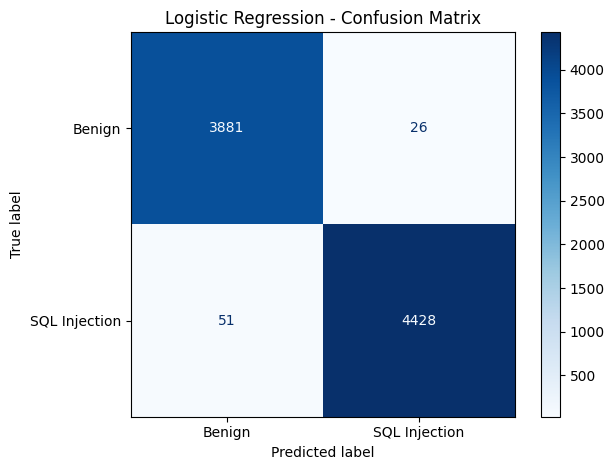

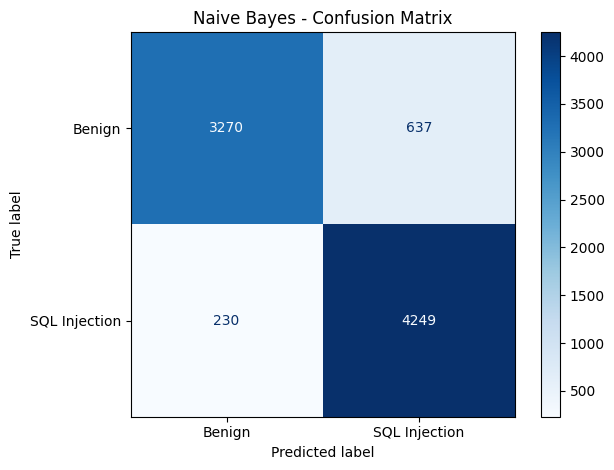

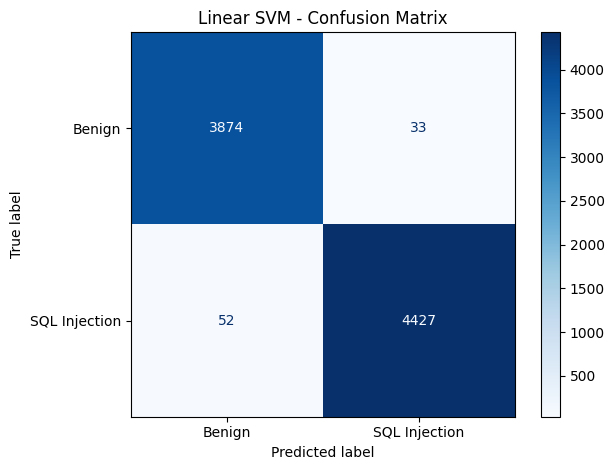

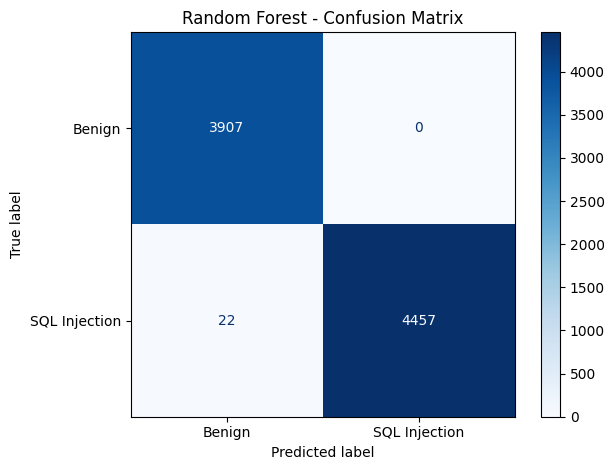

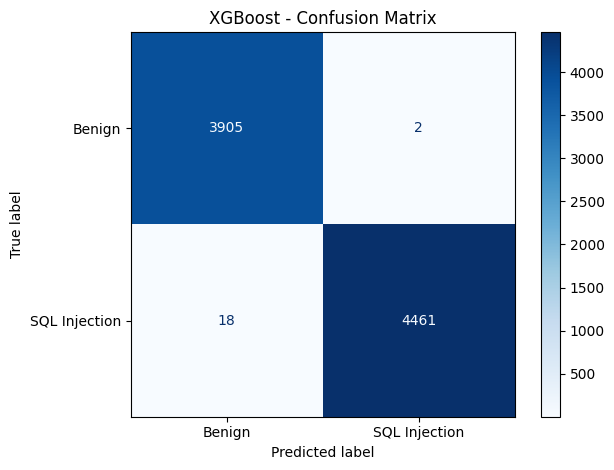

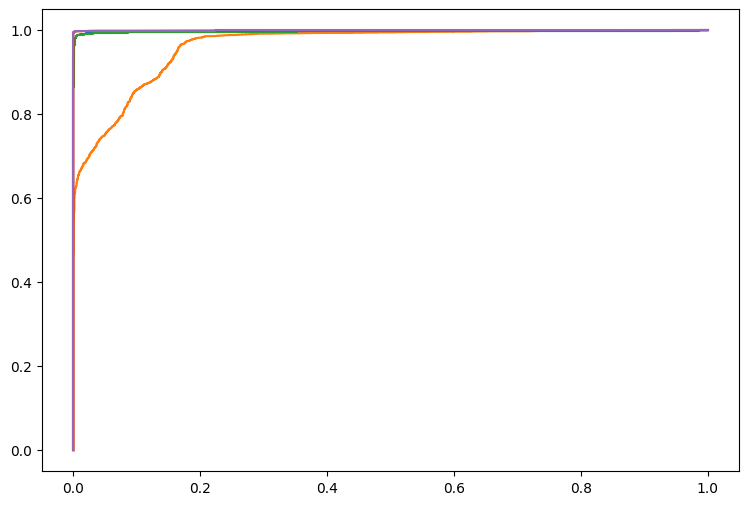

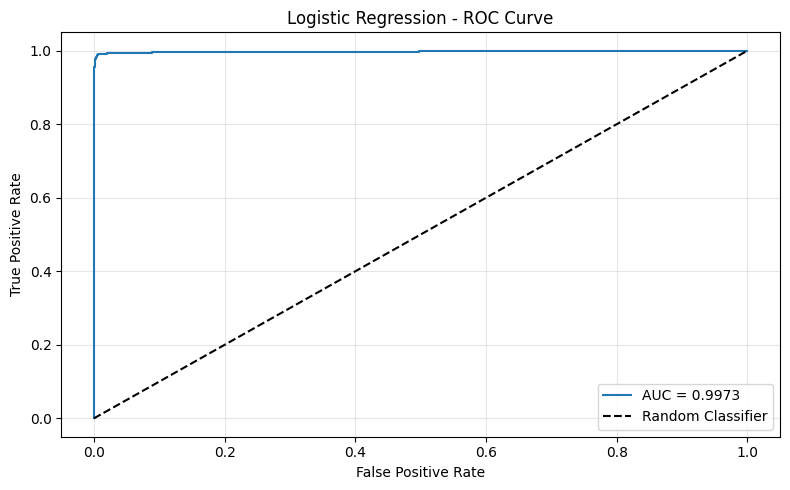

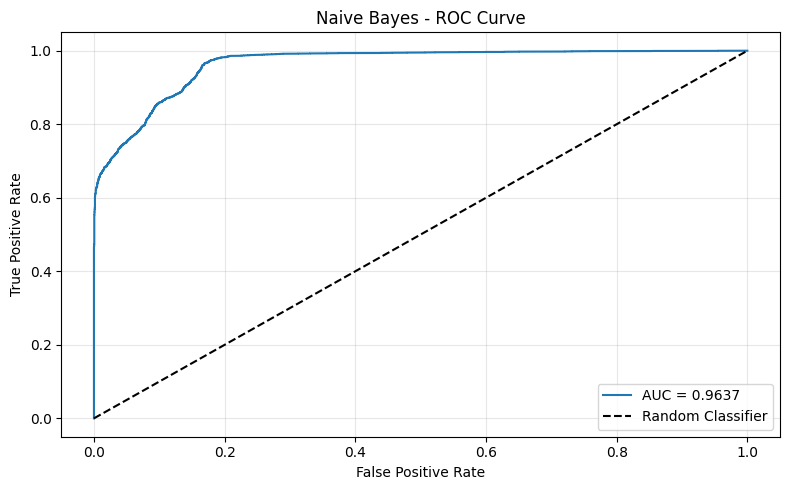

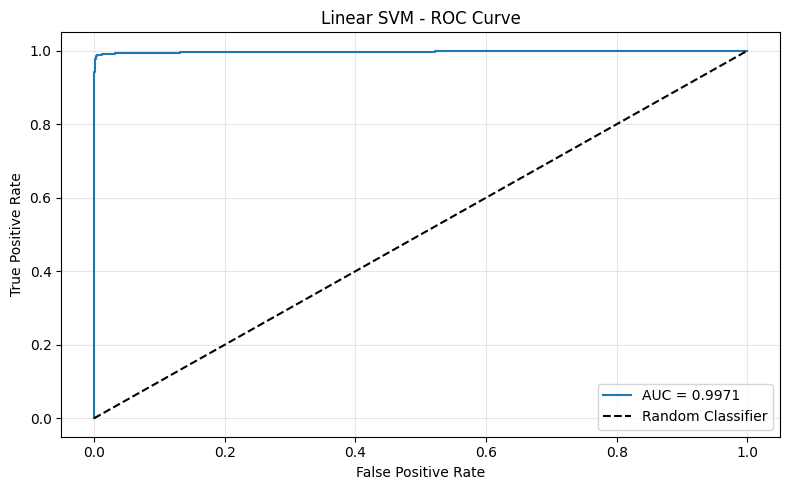

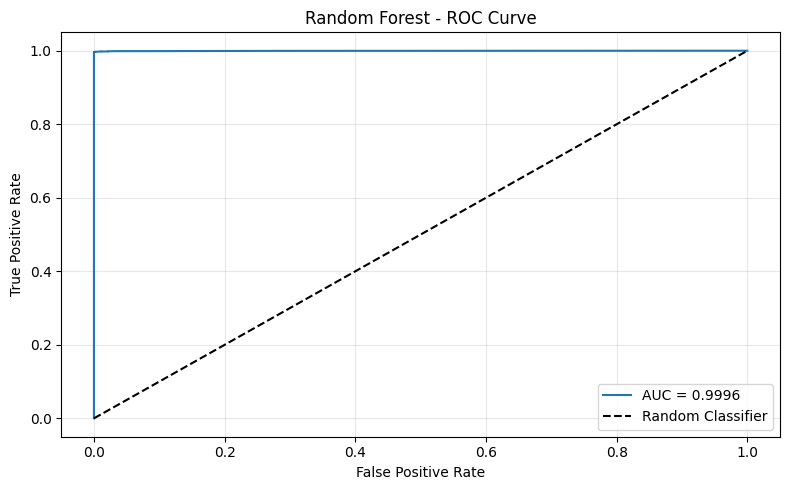

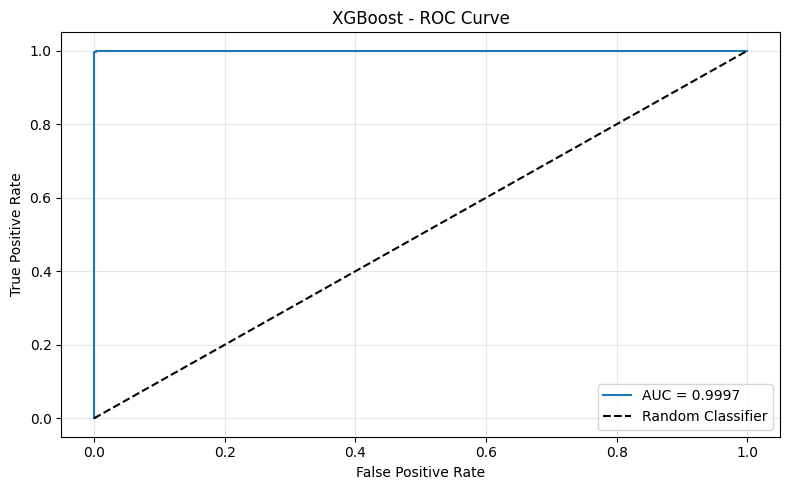

In [77]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in trained_models.items():

    y_pred = model.predict(X_test_tf)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Benign", "SQL Injection"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(name + " - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for name, model in trained_models.items():

    # Get prediction scores
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_tf)[:, 1]
    else:
        y_score = model.decision_function(X_test_tf)

    # Calculate ROC and AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

# Random classifier reference line
for name, model in trained_models.items():

    # Get prediction scores
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_tf)[:, 1]
    else:
        y_score = model.decision_function(X_test_tf)

    # Calculate ROC and AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)

    # Plot
    plt.figure(figsize=(8, 5))

    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        "k--",
        label="Random Classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(name + " - ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [78]:
from sklearn.calibration import CalibratedClassifierCV

# Calibrate Linear SVM
svm_calibrated = CalibratedClassifierCV(
    estimator=LinearSVC(
        C=10,
        random_state=51
    ),
)

svm_calibrated.fit(X_train_tf, y_train)

# Use your already trained models
voting_models = trained_models.copy()

# Replace SVM with calibrated SVM
voting_models["Linear SVM"] = svm_calibrated

# Model weights
weights = {
    "Logistic Regression": 1,
    "Naive Bayes": 0.1,
    "Linear SVM": 1,
    "Random Forest": 12,
    "XGBoost": 12
}

# Weighted Soft Voting
weighted_prob = np.zeros(len(y_test))

for name, model in voting_models.items():
    prob = model.predict_proba(X_test_tf)[:, 1]
    weighted_prob += weights[name] * prob

weighted_prob = weighted_prob / sum(weights.values())

# Final prediction
weighted_pred = (weighted_prob >= 0.5).astype(int)

# Evaluation
print("Weighted Soft Voting Ensemble")
print("Accuracy:", accuracy_score(y_test, weighted_pred))
print("Precision:", precision_score(y_test, weighted_pred, zero_division=0))
print("Recall:", recall_score(y_test, weighted_pred, zero_division=0))
print("F1:", f1_score(y_test, weighted_pred, zero_division=0))

Weighted Soft Voting Ensemble
Accuracy: 0.9977343191032674
Precision: 1.0
Recall: 0.9957579816923421
F1: 0.9978744826043181


                        Model  Accuracy  Precision   Recall       F1
          Logistic Regression  0.990818   0.994163 0.988614 0.991380
                  Naive Bayes  0.896613   0.869628 0.948649 0.907421
                   Linear SVM  0.989864   0.992601 0.988390 0.990491
                Random Forest  0.997377   1.000000 0.995088 0.997538
                      XGBoost  0.997615   0.999552 0.995981 0.997763
Weighted Soft Voting Ensemble  0.997734   1.000000 0.995758 0.997874


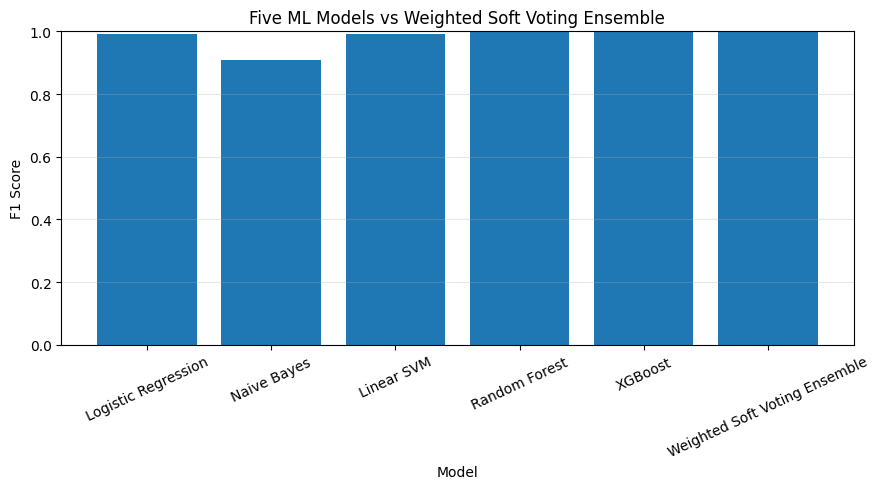

In [79]:
ensemble_results = pd.DataFrame([{
    "Model": "Weighted Soft Voting Ensemble",
    "Accuracy": accuracy_score(y_test, weighted_pred),
    "Precision": precision_score(y_test, weighted_pred, zero_division=0),
    "Recall": recall_score(y_test, weighted_pred, zero_division=0),
    "F1": f1_score(y_test, weighted_pred, zero_division=0)
}])

comparison = pd.concat(
    [results_df, ensemble_results],
    ignore_index=True
)

print(comparison[["Model", "Accuracy", "Precision", "Recall", "F1"]].to_string(index=False))

plt.figure(figsize=(9, 5))

plt.bar(comparison["Model"], comparison["F1"])

plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.title("Five ML Models vs Weighted Soft Voting Ensemble")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

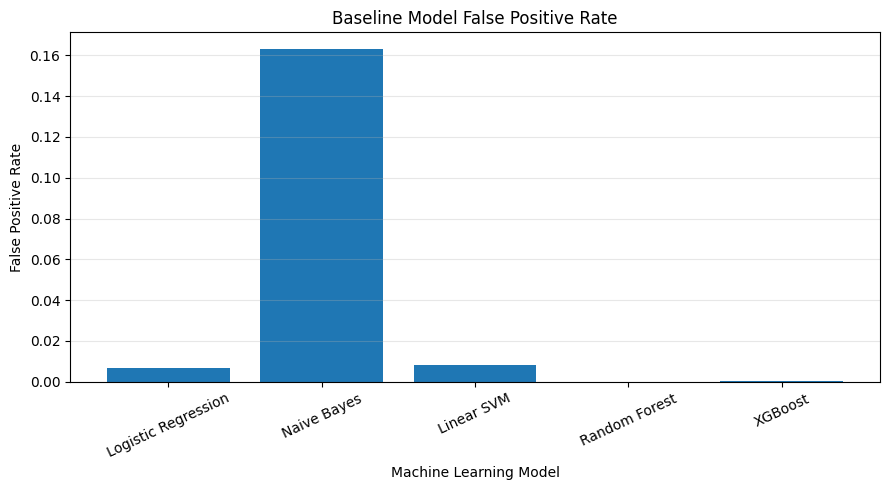

In [80]:
from sklearn.metrics import confusion_matrix

fpr_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_tf)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    fpr_results.append({
        "Model": name,
        "FPR": fpr
    })

fpr_df = pd.DataFrame(fpr_results)

plt.figure(figsize=(9, 5))

plt.bar(fpr_df["Model"], fpr_df["FPR"])

plt.xlabel("Machine Learning Model")
plt.ylabel("False Positive Rate")
plt.title("Baseline Model False Positive Rate")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

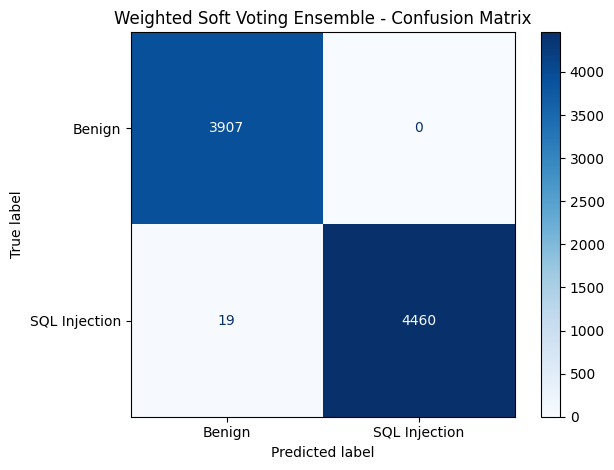

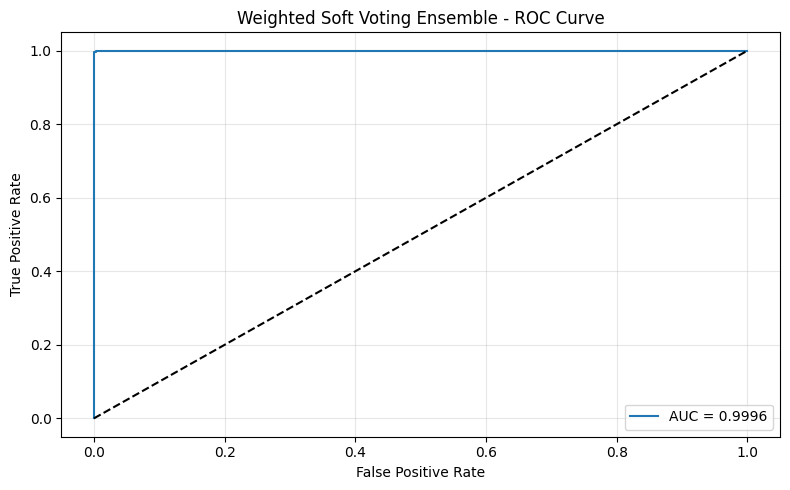

In [81]:
# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    weighted_pred,
    display_labels=["Benign", "SQL Injection"],
    cmap="Blues",
    values_format="d"
)

plt.title("Weighted Soft Voting Ensemble - Confusion Matrix")
plt.tight_layout()
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_test, weighted_prob)
auc = roc_auc_score(y_test, weighted_prob)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Weighted Soft Voting Ensemble - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [82]:
import joblib
from google.colab import files

deployment_package = {
    "models": voting_models,
    "vectorizer": vectorizer,
    "weights": weights,
    "threshold": 0.5
}

joblib.dump(deployment_package, "sql_injection_detector.joblib")

files.download("sql_injection_detector.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

      C  F1 Score
   0.01  0.971625
   0.10  0.983672
   1.00  0.988758
  10.00  0.991193
 100.00  0.991058
1000.00  0.990947

Best C: 10
Best F1: 0.991192954629019


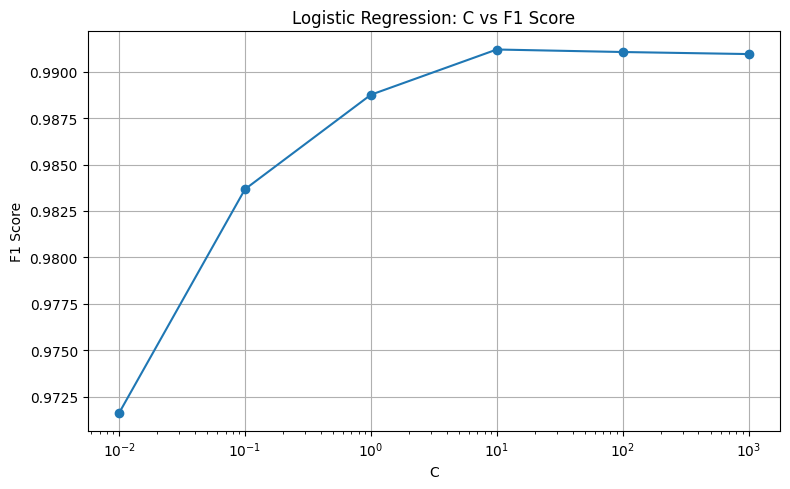

In [83]:
lr = LogisticRegression(
    random_state=51
)

lr_params = {
    "C": [0.01, 0.1, 1, 10, 100, 1000]
}

lr_grid = GridSearchCV(
    lr,
    lr_params,
    scoring="f1",
    n_jobs=-1
)

lr_grid.fit(X_train_tf, y_train)

lr_results = pd.DataFrame(lr_grid.cv_results_)

# Print numerical results
stats = lr_results[["param_C", "mean_test_score"]].copy()
stats.columns = ["C", "F1 Score"]

print(stats.to_string(index=False))

print("\nBest C:", lr_grid.best_params_["C"])
print("Best F1:", lr_grid.best_score_)

# Plot
plt.figure(figsize=(8, 5))

plt.semilogx(
    stats["C"].astype(float),
    stats["F1 Score"],
    marker="o"
)

plt.xlabel("C")
plt.ylabel("F1 Score")
plt.title("Logistic Regression: C vs F1 Score")
plt.grid(True)
plt.tight_layout()
plt.show()

    Alpha  F1 Score
  0.00001  0.910317
  0.00010  0.910317
  0.00100  0.910317
  0.01000  0.910346
  0.10000  0.910317
  1.00000  0.909829
 10.00000  0.907272
100.00000  0.901650

Best Alpha: 0.01
Best F1: 0.910345880139589


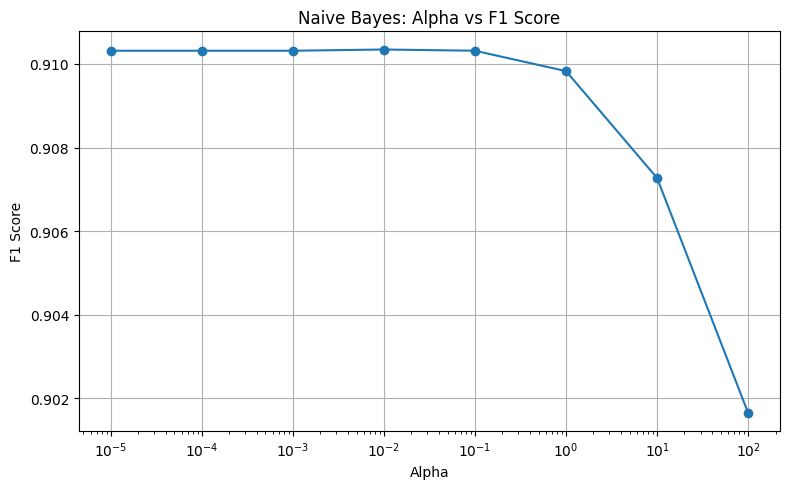

In [84]:
nb = MultinomialNB()

nb_params = {
    "alpha": [0.00001,0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
}

nb_grid = GridSearchCV(
    nb,
    nb_params,
    scoring="f1",
    n_jobs=-1
)

nb_grid.fit(X_train_tf, y_train)

nb_results = pd.DataFrame(nb_grid.cv_results_)

# Print numerical results
stats = nb_results[["param_alpha", "mean_test_score"]].copy()
stats.columns = ["Alpha", "F1 Score"]

print(stats.to_string(index=False))

print("\nBest Alpha:", nb_grid.best_params_["alpha"])
print("Best F1:", nb_grid.best_score_)

# Plot
plt.figure(figsize=(8, 5))

plt.semilogx(
    stats["Alpha"].astype(float),
    stats["F1 Score"],
    marker="o"
)

plt.xlabel("Alpha")
plt.ylabel("F1 Score")
plt.title("Naive Bayes: Alpha vs F1 Score")
plt.grid(True)
plt.tight_layout()
plt.show()

       C  F1 Score
   0.001  0.974261
   0.010  0.983582
   0.100  0.989179
   1.000  0.990357
  10.000  0.990415
 100.000  0.990277
1000.000  0.990277

Best C: 10
Best F1: 0.9904150439828807


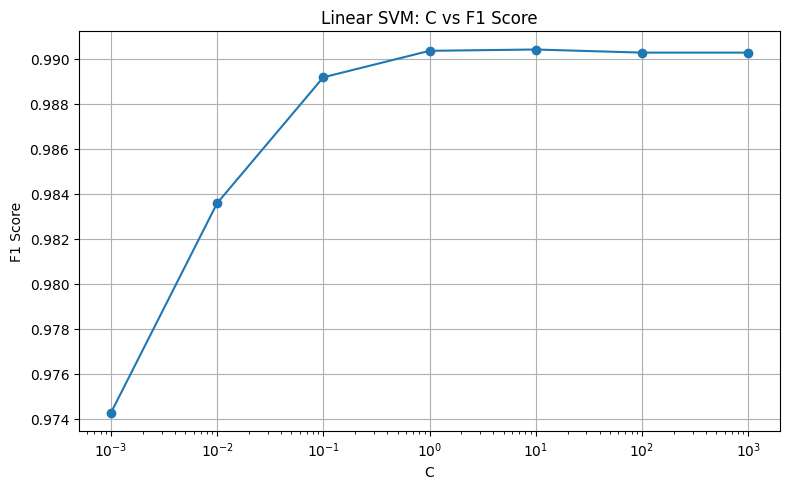

In [85]:
svm = LinearSVC(
    random_state=51
)

svm_params = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

svm_grid = GridSearchCV(
    svm,
    svm_params,
    scoring="f1",
    n_jobs=-1
)

svm_grid.fit(X_train_tf, y_train)

svm_results = pd.DataFrame(svm_grid.cv_results_)

# Print numerical results
stats = svm_results[["param_C", "mean_test_score"]].copy()
stats.columns = ["C", "F1 Score"]

print(stats.to_string(index=False))

print("\nBest C:", svm_grid.best_params_["C"])
print("Best F1:", svm_grid.best_score_)

# Plot
plt.figure(figsize=(8, 5))

plt.semilogx(
    stats["C"].astype(float),
    stats["F1 Score"],
    marker="o"
)

plt.xlabel("C")
plt.ylabel("F1 Score")
plt.title("Linear SVM: C vs F1 Score")
plt.grid(True)
plt.tight_layout()
plt.show()

 Number of Trees  F1 Score
               5  0.995945
              10  0.996417
              25  0.996895
              50  0.997118
              75  0.997146
             100  0.997091

Best n_estimators: 75
Best F1: 0.9971464280519315


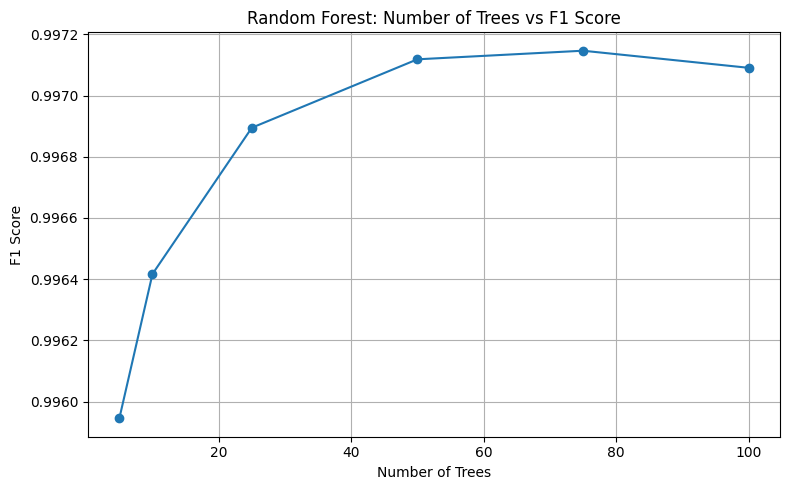

In [86]:
rf = RandomForestClassifier(
    random_state=51,
    n_jobs=-1
)

rf_params = {
    "n_estimators": [5, 10, 25, 50, 75, 100]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train_tf, y_train)

rf_results = pd.DataFrame(rf_grid.cv_results_)

# Print numerical results
stats = rf_results[["param_n_estimators", "mean_test_score"]].copy()
stats.columns = ["Number of Trees", "F1 Score"]

print(stats.to_string(index=False))

print("\nBest n_estimators:", rf_grid.best_params_["n_estimators"])
print("Best F1:", rf_grid.best_score_)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(
    stats["Number of Trees"].astype(int),
    stats["F1 Score"],
    marker="o"
)

plt.xlabel("Number of Trees")
plt.ylabel("F1 Score")
plt.title("Random Forest: Number of Trees vs F1 Score")
plt.grid(True)
plt.tight_layout()
plt.show()

 Number of Trees  F1 Score
             100  0.996727
             150  0.997064
             200  0.997260
             250  0.997427
             300  0.997456
             350  0.997400
             400  0.997428
             450  0.997400

Best n_estimators: 300
Best F1: 0.9974557829603355


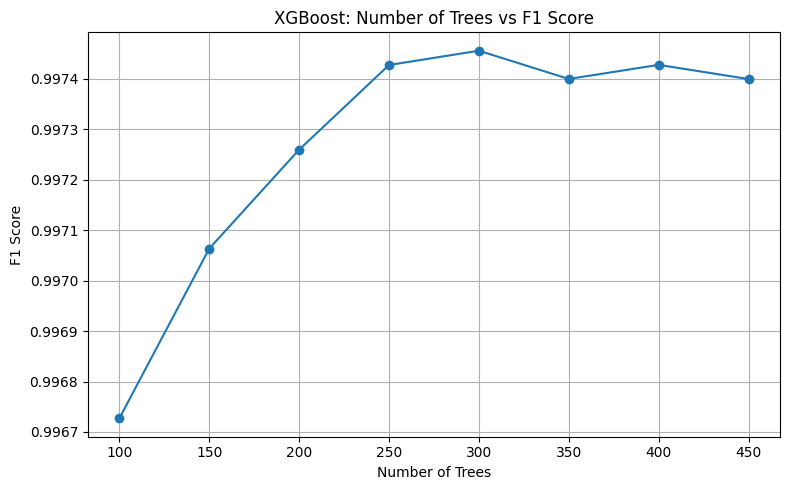

In [87]:
xgb = XGBClassifier(
    max_depth=3,
    random_state=51,
    tree_method="hist",
    n_jobs=-1
)

xgb_params = {
    "n_estimators": [100, 150, 200, 250, 300, 350, 400, 450]
}

xgb_grid = GridSearchCV(
    xgb,
    xgb_params,
    scoring="f1",
    n_jobs=-1
)

xgb_grid.fit(X_train_tf, y_train)

xgb_results = pd.DataFrame(xgb_grid.cv_results_)

# Print numerical results
stats = xgb_results[["param_n_estimators", "mean_test_score"]].copy()
stats.columns = ["Number of Trees", "F1 Score"]

print(stats.to_string(index=False))

print("\nBest n_estimators:", xgb_grid.best_params_["n_estimators"])
print("Best F1:", xgb_grid.best_score_)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(
    stats["Number of Trees"].astype(int),
    stats["F1 Score"],
    marker="o"
)

plt.xlabel("Number of Trees")
plt.ylabel("F1 Score")
plt.title("XGBoost: Number of Trees vs F1 Score")
plt.grid(True)
plt.tight_layout()
plt.show()